# 문장 임베딩 압축 실험
**궁금한 점:** 문장 임베딩을 크기순으로 정렬하고,샘플링과 보간법으로 압축/복원할 수 있지 않을까?

진행 순서: **임베딩 만들기 → 정렬 → 샘플링 → 보간 → 원래 순서로 되돌리기 → 비교**

- 한국어 10문장 + 영어 10문장
- 남길 값의 개수: **8, 16, 32, 48, 64개**
- 선택 방법: Uniform, Chebyshev
- 복원 방법: Linear, Cubic Spline
- 비교 기준: 평균 코사인 유사도, 평균 MSE, 배열 저장량
- 정렬하지 않는 대조군도 함께 비교한다.
- 그림은 **복원 예시**와 **정확도 비교**

## 1. 필요한 라이브러리 설치


In [1]:
# 이미 설치된 패키지는 그대로 사용한다.
%pip install -q numpy scipy pandas matplotlib sentence-transformers


## 2. 준비
실험 크기를 바꾸려면 아래의 `SAMPLE_COUNTS`만 수정하면 된다.
모델 다운로드가 어려우면 `USE_SYNTHETIC = True`로 바꿔 난수로 코드를 시험할 수 있다. 합성 데이터의 결과는 실제 문장 임베딩 결과가 아니다.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from IPython.display import display

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
SAMPLE_COUNTS = [8,16, 32,48, 64]
USE_SYNTHETIC = False

# 기존 노트북의 실험 결과와 다른 폴더에 저장한다.
output_dir = Path("results_simple/synthetic" if USE_SYNTHETIC else "results_simple")
output_dir.mkdir(parents=True, exist_ok=True)
data_label = "Synthetic test" if USE_SYNTHETIC else "Sentence embeddings"


## 3. 문장 20개를 임베딩으로 바꾸기
임베딩은 문장을 숫자 벡터로 표현한 것이다. 여기서는 작은 다국어 모델을 사용한다.
첫 실행 이후에는 모델 파일을 재사용한다. 임베딩 값은 저장량 계산을 위해 float32로 맞춘다.


In [3]:
sentences = [
    "오늘 날씨가 맑다.",
    "도서관에서 책을 읽었다.",
    "고양이가 소파에서 잠을 잔다.",
    "친구와 공원에서 산책했다.",
    "따뜻한 커피를 마셨다.",
    "기차가 역을 출발했다.",
    "학생이 수학 문제를 풀었다.",
    "바다 위로 해가 떠오른다.",
    "컴퓨터로 실험 결과를 정리했다.",
    "음악을 들으며 방을 청소했다.",
    "A bird is singing in the garden.",
    "The train arrived early.",
    "I cooked dinner for my family.",
    "She is learning a new language.",
    "The mountain is covered with snow.",
    "We watched a movie yesterday.",
    "The scientist measured the temperature.",
    "A dog is running after a ball.",
    "He fixed his bicycle.",
    "The library is quiet in the morning.",
]

if USE_SYNTHETIC:
    rng = np.random.default_rng(42)
    embeddings = rng.normal(0, 0.1, size=(len(sentences), 384)).astype(np.float32)
    print("주의: 합성 데이터 테스트입니다.")
else:
    import torch
    from sentence_transformers import SentenceTransformer

    torch.set_num_threads(4)
    model = SentenceTransformer(
        MODEL_NAME, device="cpu", cache_folder="results/cache/models"
    )
    embeddings = model.encode(sentences, show_progress_bar=True).astype(np.float32)

D = embeddings.shape[1]
SAMPLE_COUNTS = [k for k in SAMPLE_COUNTS if 2 <= k <= D]
assert SAMPLE_COUNTS, "차원 수 이하이고 2 이상인 샘플 수를 지정하세요."
assert np.isfinite(embeddings).all()
# 0부터 D-1까지 저장할 수 있는 작은 정수형을 선택한다. 384차원은 uint16이다.
index_dtype = np.min_scalar_type(D - 1)
print("임베딩 크기:", embeddings.shape)
print("남길 값의 개수:", SAMPLE_COUNTS)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

임베딩 크기: (20, 384)
남길 값의 개수: [8, 16, 32, 48, 64]


In [4]:
print(embeddings.shape)

(20, 384)


## 4. 정렬했다가 원래 순서로 되돌리기
`np.argsort()`는 값이 작은 순서대로 **원래 위치**를 알려 준다.
예를 들어 [0.3, -0.2, 0.1]의 정렬 순서는 [1, 2, 0]이다.

이 순서를 함께 저장해야 나중에 원래 벡터로 되돌릴 수 있다.
`restored[order] = sorted_vector`가 역정렬의 핵심이다.


In [5]:
vector = embeddings[0]
order = np.argsort(vector)
sorted_vector = vector[order]

restored = np.empty_like(vector)
restored[order] = sorted_vector
assert np.array_equal(vector, restored)
print("정렬과 역정렬 확인 완료")


정렬과 역정렬 확인 완료


## 5. 필요한 함수 3개
**샘플 선택:** Uniform은 일정한 간격으로 고른다. Chebyshev-Lobatto는 양 끝부분을 더 촘촘히 고른다. 둘 다 양 끝점을 포함한다.

Chebyshev 위치를 정수로 반올림하면 중복이 생길 수 있다. 중복을 제거한 뒤 가장 넓은 빈 구간의 중간에 점을 추가해 개수를 맞춘다. 따라서 실제 사용한 위치는 연속 Chebyshev 노드를 정수 격자에 맞게 보정한 것이다.

**복원:** Linear는 점 사이를 직선으로 연결한다. Cubic Spline은 자연 경계조건을 사용하는 3차 곡선으로 연결한다.

**평가:** 코사인 유사도는 벡터 방향이 비슷할수록 1에 가깝다. MSE는 원본과 복원값의 차이를 제곱해서 평균 낸 것으로, 작을수록 좋다.


In [6]:
def sampling_indices(dimension, count, method):
    # 샘플 위치를 선택한다.
    assert 2 <= count <= dimension
    if method == "uniform":
        positions = np.linspace(0, dimension - 1, count)
    else:
        theta = np.linspace(0, np.pi, count)
        positions = (dimension - 1) * (1 - np.cos(theta)) / 2

    indices = np.unique(np.rint(positions).astype(int))
    # 중복 때문에 부족한 점을 가장 넓은 구간의 중간에 추가한다.
    while len(indices) < count:
        gap = np.argmax(np.diff(indices))
        middle = (indices[gap] + indices[gap + 1]) // 2
        indices = np.sort(np.append(indices, middle))
    return indices

def interpolate(indices, values, dimension, method):
    # 샘플 값으로 전체 차원의 값을 복원한다.
    x = np.arange(dimension)
    if method == "linear":
        return np.interp(x, indices, values)
    return CubicSpline(indices, values, bc_type="natural")(x)

def cosine_similarity(a, b):
    # 계산할 때는 float64를 사용한다.
    a, b = a.astype(float), b.astype(float)
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    assert denominator > 0, "영벡터의 코사인 유사도는 정의되지 않습니다."
    return np.clip(np.dot(a, b) / denominator, -1, 1)


## 6. 간단한 확인
선택한 인덱스가 중복 없이 정확히 k개인지 확인한다.
전체 차원을 남기면 두 보간법 모두 원본으로 복원되어야 한다.


In [7]:
for sampling in ["uniform", "chebyshev"]:
    for k in SAMPLE_COUNTS + [D]:
        indices = sampling_indices(D, k, sampling)
        assert len(indices) == len(np.unique(indices)) == k
        assert indices[0] == 0 and indices[-1] == D - 1
        for method in ["linear", "cubic"]:
            result = interpolate(indices, sorted_vector[indices], D, method)
            assert result.shape == (D,) and np.isfinite(result).all()
            if k == D:
                assert np.allclose(result, sorted_vector)

assert np.isclose(cosine_similarity(vector, vector), 1)
assert np.isclose(cosine_similarity(np.array([1., 0.]), np.array([0., 1.])), 0)
print("테스트 통과")


테스트 통과


## 7. 전체 실험
아래 반복문은 **선택 방법 → 복원 방법 → 샘플 수 → 문장** 순서로 실행된다.
정확도는 반드시 역정렬을 한 뒤 원본과 비교한다.

저장량은 다음 배열들의 byte 수를 더한다.

**샘플 값(float32) + 샘플 위치(정수) + 정렬 순서(정수)**

감소율(%) = 100 × (1 − 압축 배열의 byte 수 / 원본 배열의 byte 수)

쉽게 이해할 수 있도록 배열의 저장량만 계산한다. 파일 헤더와 Python 객체 비용은 제외하므로 실제 파일 크기와는 다르다. 정렬 순서 비용은 반드시 포함한다. 감소율이 음수라면 원본보다 저장량이 커진 것이다.


In [8]:
rows = []

for sampling in ["uniform", "chebyshev"]:
    for method in ["linear", "cubic"]:
        for k in SAMPLE_COUNTS:
            indices = sampling_indices(D, k, sampling)
            for vector in embeddings:
                order = np.argsort(vector)
                sorted_vector = vector[order]
                sampled_values = sorted_vector[indices]

                reconstructed = interpolate(indices, sampled_values, D, method)
                restored = np.empty(D)
                restored[order] = reconstructed

                stored_bytes = (
                    sampled_values.nbytes
                    + indices.astype(index_dtype).nbytes
                    + order.astype(index_dtype).nbytes
                )
                rows.append({
                    "method": sampling + " + " + method,
                    "k": k,
                    "cosine": cosine_similarity(vector, restored),
                    "mse": np.mean((vector.astype(float) - restored) ** 2),
                    "stored_bytes": stored_bytes,
                    "reduction_pct": 100 * (1 - stored_bytes / vector.nbytes),
                })

# 대조군: 정렬 없이 Uniform + Linear를 적용한다.
for k in SAMPLE_COUNTS:
    indices = sampling_indices(D, k, "uniform")
    for vector in embeddings:
        restored = interpolate(indices, vector[indices], D, "linear")
        stored_bytes = vector[indices].nbytes + indices.astype(index_dtype).nbytes
        rows.append({
            "method": "unsorted control",
            "k": k,
            "cosine": cosine_similarity(vector, restored),
            "mse": np.mean((vector.astype(float) - restored) ** 2),
            "stored_bytes": stored_bytes,
            "reduction_pct": 100 * (1 - stored_bytes / vector.nbytes),
        })

# 같은 조건의 20개 문장 결과를 평균 낸다.
results = pd.DataFrame(rows).groupby(["method", "k"], as_index=False).mean()
assert len(results) == 5 * len(SAMPLE_COUNTS)
results.to_csv(output_dir / "results.csv", index=False)
print(data_label, "| 각 행은 문장 20개의 평균입니다.")
display(results.round(6))


Sentence embeddings | 각 행은 문장 20개의 평균입니다.


,method,k,cosine,mse,stored_bytes,reduction_pct
0,chebyshev + cubic,8,0.987581,0.001865,816.0,46.875
1,chebyshev + cubic,16,0.998610,0.000200,864.0,43.750
2,chebyshev + cubic,32,0.999703,0.000043,960.0,37.500
3,chebyshev + cubic,48,0.999832,0.000025,1056.0,31.250
4,chebyshev + cubic,64,0.999900,0.000014,1152.0,25.000
5,chebyshev + linear,8,0.997215,0.000898,816.0,46.875
6,chebyshev + linear,16,0.999421,0.000105,864.0,43.750
7,chebyshev + linear,32,0.999791,0.000031,960.0,37.500
8,chebyshev + linear,48,0.999837,0.000024,1056.0,31.250
9,chebyshev + linear,64,0.999909,0.000013,1152.0,25.000


## 8. 그림 1 — 한 문장의 복원 모습
첫 문장의 정렬된 임베딩과 복원 결과를 비교한다. 검은 선은 원본, 점은 남긴 샘플이다.
Cubic Spline은 정렬된 값 사이에서도 튀거나 감소하는 구간이 생길 수 있다(overshoot). 항상 Linear보다 정확한 것은 아니다.


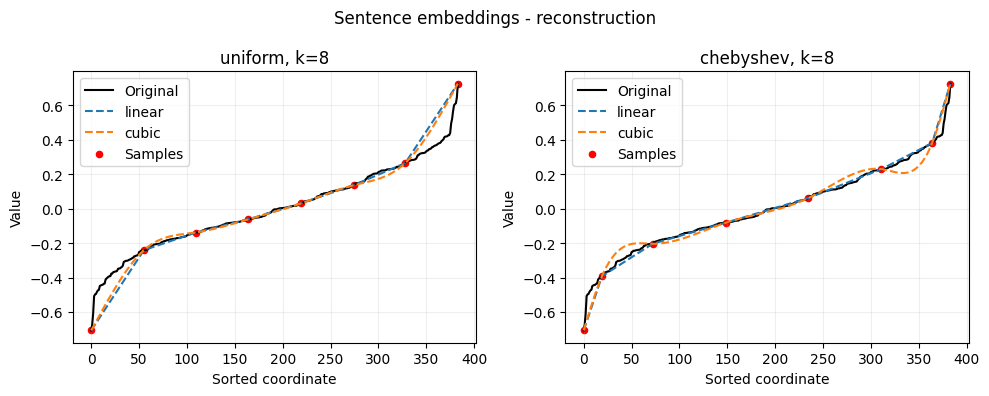

In [9]:
vector = embeddings[0]
sorted_vector = np.sort(vector)
k = SAMPLE_COUNTS[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, sampling in zip(axes, ["uniform", "chebyshev"]):
    indices = sampling_indices(D, k, sampling)
    ax.plot(sorted_vector, color="black", label="Original")
    for method in ["linear", "cubic"]:
        reconstructed = interpolate(indices, sorted_vector[indices], D, method)
        ax.plot(reconstructed, "--", label=method)
    ax.scatter(indices, sorted_vector[indices], color="red", s=20, label="Samples")
    ax.set_title(sampling + f", k={k}")
    ax.set_xlabel("Sorted coordinate")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle(data_label + " - reconstruction")
fig.tight_layout()
fig.savefig(output_dir / "reconstruction.png", dpi=200)
plt.show()


## 9. 그림 2 — 샘플 수와 정확도
주 실험 4가지 방법의 **평균 코사인 유사도**를 비교한다.
방법 간 차이를 읽기 쉽게 정렬한 조건만 그림에 표시한다. 비정렬 대조군의 값은 위 결과표에서 비교한다. 세 점을 잇는 선은 경향을 보기 위한 것이며, 그 사이의 샘플 수는 실험하지 않았다.
<직접 그린 그림>


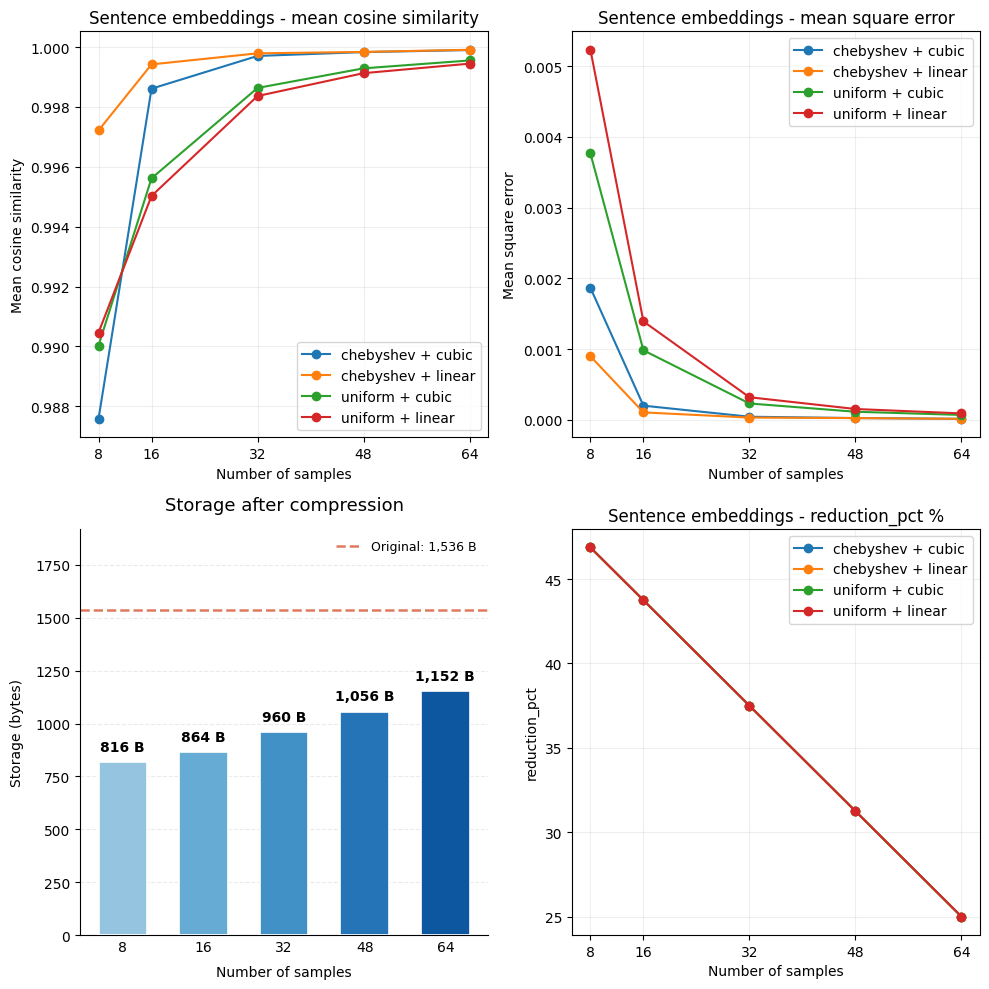

In [35]:
fig, axes = plt.subplots(2,2,figsize=(10, 10))
main_results = results[results["method"] != "unsorted control"]

for name, group in main_results.groupby("method"):
    axes[0][0].plot(group["k"], group["cosine"], "o-", label=name)

axes[0][0].set_title(data_label + " - mean cosine similarity")
axes[0][0].set_xlabel("Number of samples")
axes[0][0].set_ylabel("Mean cosine similarity")
axes[0][0].set_xticks(SAMPLE_COUNTS)
axes[0][0].grid(alpha=0.2)
axes[0][0].legend()

for name, group in main_results.groupby("method"):
    axes[0][1].plot(group["k"], group["mse"], "o-", label=name)

axes[0][1].set_title(data_label + " - mean square error")
axes[0][1].set_xlabel("Number of samples")
axes[0][1].set_ylabel("Mean square error")
axes[0][1].set_xticks(SAMPLE_COUNTS)
axes[0][1].grid(alpha=0.2)
axes[0][1].legend()

# 왼쪽 아래: 저장량 막대그래프
ax = axes[1][0]
ax.clear()
# 네 방법의 저장량이 같으므로 샘플 수별로 하나만 표시
storage = (
    main_results.groupby("k", as_index=False)["stored_bytes"]
    .first()
    .sort_values("k")
)
x = np.arange(len(storage))
original_bytes = embeddings[0].nbytes
colors = plt.cm.Blues(np.linspace(0.4, 0.85, len(storage)))
bars = ax.bar(
    x,
    storage["stored_bytes"],
    width=0.6,
    color=colors,
    edgecolor="white",
    linewidth=1.2,
    zorder=3,
)
# 막대 위에 저장량 표시
ax.bar_label(
    bars,
    labels=[f"{value:,.0f} B" for value in storage["stored_bytes"]],
    padding=6,
    fontsize=10,
    fontweight="bold",
)
# 원본 저장량 기준선
ax.axhline(
    original_bytes,
    color="#E07A5F",
    linestyle="--",
    linewidth=1.8,
    label=f"Original: {original_bytes:,.0f} B",
    zorder=2,
)
ax.set_title("Storage after compression", fontsize=13, pad=14)
ax.set_xlabel("Number of samples", labelpad=8)
ax.set_ylabel("Storage (bytes)", labelpad=8)
ax.set_xticks(x, storage["k"].astype(int))
ax.set_ylim(
    0,
    max(original_bytes, storage["stored_bytes"].max()) * 1.25,
)

ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(loc="upper right", frameon=False, fontsize=9)

for name, group in main_results.groupby("method"):
    axes[1][1].plot(group["k"], group["reduction_pct"], "o-", label=name)

axes[1][1].set_title(data_label + " - reduction_pct %")
axes[1][1].set_xlabel("Number of samples")
axes[1][1].set_ylabel("reduction_pct")
axes[1][1].set_xticks(SAMPLE_COUNTS)
axes[1][1].grid(alpha=0.2)
axes[1][1].legend()

fig.tight_layout()
fig.savefig(output_dir / "accuracy.png", dpi=200)
plt.show()


확실히 GPT가 그래프를 더 잘 그린다

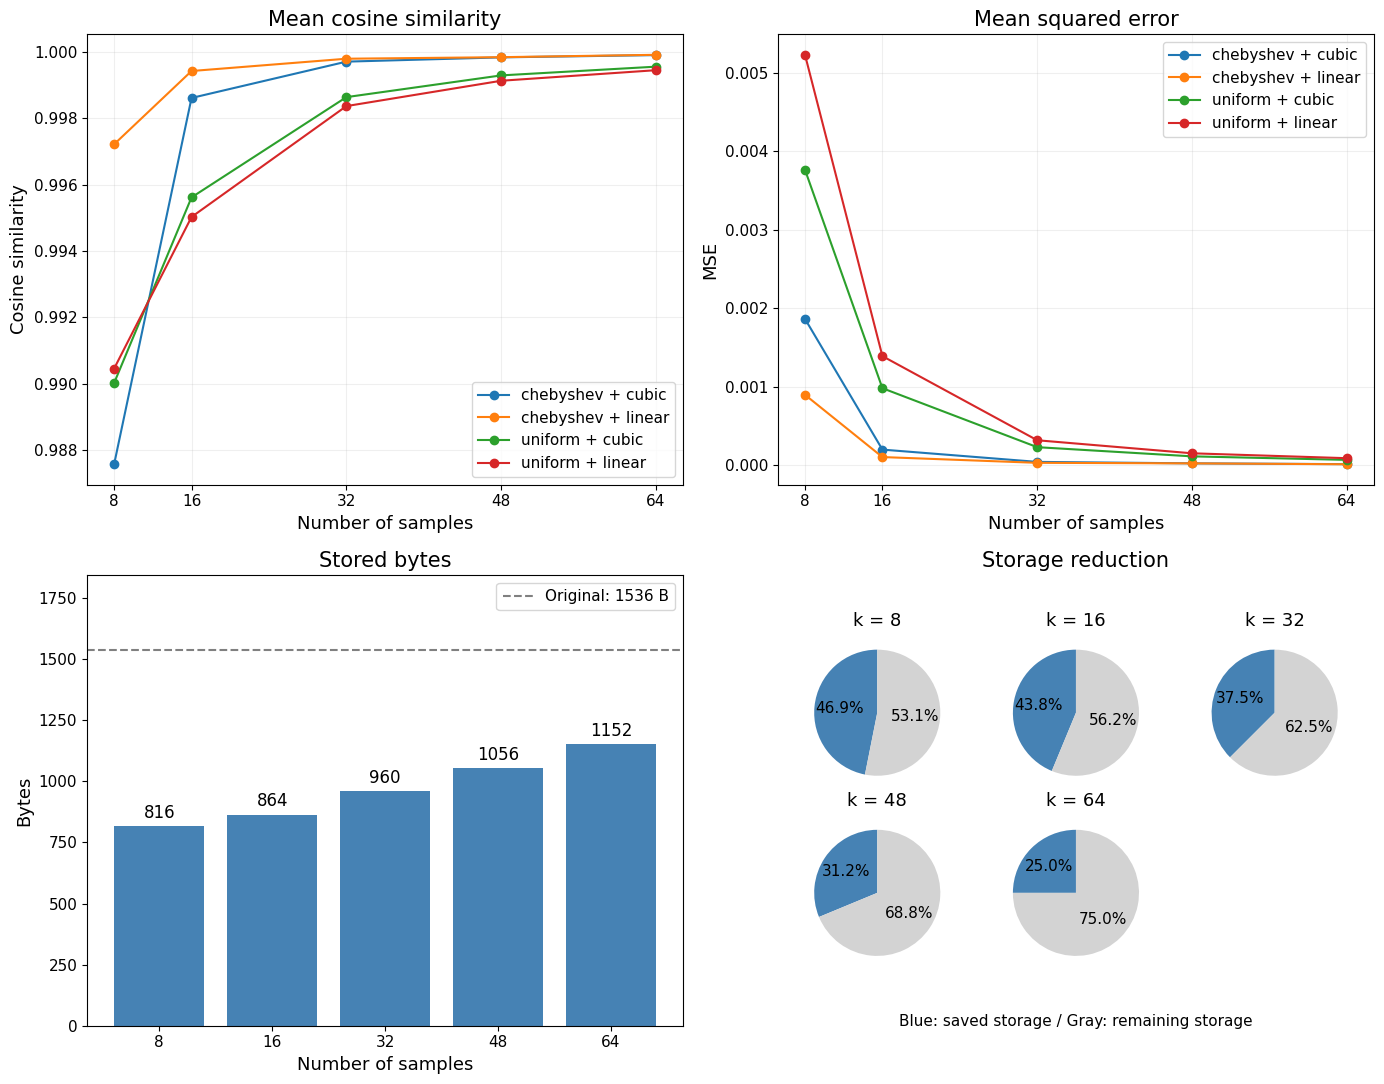

In [39]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
})

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

main_results = results[
    results["method"] != "unsorted control"
]

# 1. 코사인 유사도
for name, group in main_results.groupby("method"):
    group = group.sort_values("k")
    axes[0, 0].plot(group["k"], group["cosine"], "o-", label=name)

axes[0, 0].set_title("Mean cosine similarity")
axes[0, 0].set_xlabel("Number of samples")
axes[0, 0].set_ylabel("Cosine similarity")
axes[0, 0].set_xticks(SAMPLE_COUNTS)
axes[0, 0].grid(alpha=0.2)
axes[0, 0].legend(fontsize=11)

# 2. MSE
for name, group in main_results.groupby("method"):
    group = group.sort_values("k")
    axes[0, 1].plot(group["k"], group["mse"], "o-", label=name)

axes[0, 1].set_title("Mean squared error")
axes[0, 1].set_xlabel("Number of samples")
axes[0, 1].set_ylabel("MSE")
axes[0, 1].set_xticks(SAMPLE_COUNTS)
axes[0, 1].grid(alpha=0.2)
axes[0, 1].legend(fontsize=11)

# 같은 샘플 수에서는 메서드별 저장량이 같음
storage = (
    main_results.groupby("k")[["stored_bytes", "reduction_pct"]]
    .first()
    .sort_index()
)

# 3. 저장량: 샘플 수별 막대 하나
x = np.arange(len(storage))
original_bytes = embeddings[0].nbytes

bars = axes[1, 0].bar(
    x, storage["stored_bytes"], color="steelblue"
)
axes[1, 0].bar_label(
    bars, fmt="%.0f", padding=3, fontsize=12
)

axes[1, 0].axhline(
    original_bytes,
    color="gray",
    linestyle="--",
    label=f"Original: {original_bytes} B",
)

axes[1, 0].set_title("Stored bytes")
axes[1, 0].set_xlabel("Number of samples")
axes[1, 0].set_ylabel("Bytes")
axes[1, 0].set_xticks(x, storage.index)
axes[1, 0].set_ylim(
    0, max(original_bytes, storage["stored_bytes"].max()) * 1.2
)
axes[1, 0].legend(fontsize=11)

# 4. 저장량 감소율: 샘플 수마다 원그래프 하나
ax = axes[1, 1]
ax.set_title("Storage reduction")
ax.axis("off")

ncols = 3
nrows = int(np.ceil(len(storage) / ncols))

for i, (k, row) in enumerate(storage.iterrows()):
    r, c = divmod(i, ncols)

    pie_ax = ax.inset_axes([
        c / ncols,
        0.12 + (nrows - 1 - r) * 0.8 / nrows,
        1 / ncols,
        0.7 / nrows,
    ])

    saved = row["reduction_pct"]

    if 0 <= saved <= 100:
        pie_ax.pie(
            [saved, 100 - saved],
            colors=["steelblue", "lightgray"],
            autopct="%.1f%%",
            startangle=90,
            textprops={"fontsize": 11},
        )
    else:
        pie_ax.text(
            0.5, 0.5,
            f"Reduction:\n{saved:.1f}%",
            ha="center", va="center",
            fontsize=12,
            transform=pie_ax.transAxes,
        )
        pie_ax.axis("off")

    pie_ax.set_title(f"k = {k}", fontsize=13)

ax.text(
    0.5, 0,
    "Blue: saved storage / Gray: remaining storage",
    ha="center",
    fontsize=11,
    transform=ax.transAxes,
)

fig.tight_layout()
fig.savefig(output_dir / "accuracy.png", dpi=200)
plt.show()

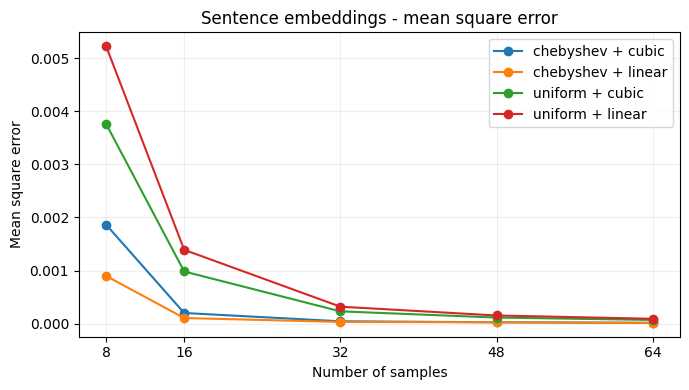

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
main_results = results[results["method"] != "unsorted control"]

for name, group in main_results.groupby("method"):
    ax.plot(group["k"], group["cosine"], "o-", label=name)

ax.set_title(data_label + " - mean square error")
ax.set_xlabel("Number of samples")
ax.set_ylabel("Mean square")
ax.set_xticks(SAMPLE_COUNTS)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "accuracy.png", dpi=200)
plt.show()


## 10. 결과 읽기
아래에서는 평균 코사인 유사도 0.95 이상이고 저장량도 줄어든 조건을 찾는다.
그중 저장량이 가장 적은 조건을 선택하고, 저장량이 같으면 코사인 유사도가 높은 쪽을 고른다.

이 결과는 **이번 20문장과 시험한 샘플 수**에 대한 것이다. 모든 문장의 유사도가 0.95 이상이라는 뜻은 아니다.

직접 생각해 볼 질문:
- 샘플 수를 늘리면 코사인 유사도와 MSE가 어떻게 바뀌는가?
- Chebyshev와 Uniform 중 어떤 방법이 더 정확한가?
- 정렬 순서까지 저장하면 실제로 얼마나 저장량을 줄일 수 있는가?

기본 결과 파일은 `results_simple/results.csv`, `reconstruction.png`, `accuracy.png`이다. 합성 테스트 결과는 그 아래 `synthetic/`에 따로 저장한다. Colab에서는 왼쪽 파일 목록에서 필요한 결과를 내려받으면 된다.


In [12]:
candidates = results[
    (results["cosine"] >= 0.95) & (results["reduction_pct"] > 0)
]
if candidates.empty:
    print("현재 조건에서는 정확도 0.95와 저장량 감소를 동시에 만족하지 못했습니다.")
else:
    best = candidates.sort_values(
        ["stored_bytes", "cosine"], ascending=[True, False]
    ).iloc[0]
    print("이번 실험에서 선택한 조건:", best["method"], ", k =", int(best["k"]))
    print("평균 코사인 유사도:", round(best["cosine"], 4))
    print("배열 기준 저장량 감소율:", round(best["reduction_pct"], 2), "%")

if USE_SYNTHETIC:
    print("합성 데이터 결과이므로 문장 임베딩에 대한 결론으로 사용하지 마세요.")
print("결과 폴더:", output_dir)


이번 실험에서 선택한 조건: chebyshev + linear , k = 8
평균 코사인 유사도: 0.9972
배열 기준 저장량 감소율: 46.88 %
결과 폴더: results_simple


## 11. Vec2Text 모델을 이용한 실제 문장 유사도 테스트


AI의 도움을 받았습니다

In [13]:
%pip install -q numpy scipy pandas matplotlib vec2text==0.0.13 transformers==4.49.0 sentence-transformers==3.4.1 "optimum<2" "datasets<4" "accelerate>=0.26,<2" bert-score jiwer sentencepiece

In [14]:
from importlib.metadata import version

import vec2text
from bert_score import score
from jiwer import wer

for name in ["vec2text", "transformers", "huggingface-hub"]:
    print(name, version(name))

print("실험에 필요한 라이브러리 불러오기 성공")

vec2text 0.0.13
transformers 4.49.0
huggingface-hub 0.36.2
실험에 필요한 라이브러리 불러오기 성공


In [15]:
import numpy as np
import pandas as pd
import torch
import vec2text
from bert_score import score
from jiwer import wer
from IPython.display import display

# 이 설정만 바꾸면서 실험하면 됩니다.
V2T_K = 32
V2T_SAMPLING = "chebyshev"   # "uniform" 또는 "chebyshev"
V2T_INTERPOLATION = "linear" # "linear" 또는 "cubic"
V2T_STEPS = 5               # 더 오래 복원하려면 20으로 변경

assert torch.cuda.is_available(), "Colab에서 GPU 런타임을 선택하세요."
torch.manual_seed(42)

# 기존 문장 목록에서 영어 문장 5개만 사용합니다.
v2t_texts = [s for s in sentences if s.isascii()][:5]
assert v2t_texts, "영어 문장이 필요합니다."

# 1. GTR 임베딩을 복원할 수 있는 Vec2Text 모델
corrector = vec2text.load_pretrained_corrector("gtr-base")
corrector.model.to("cuda").eval()
corrector.inversion_trainer.model.to("cuda").eval()

# 2. 복원 모델과 동일한 인코더로 원본 임베딩 생성
tokens = corrector.embedder_tokenizer(
    v2t_texts,
    return_tensors="pt",
    padding="max_length",
    truncation=True,
    max_length=128,
).to("cuda")

with torch.no_grad():
    gtr_embeddings = corrector.inversion_trainer.call_embedding_model(
        input_ids=tokens["input_ids"],
        attention_mask=tokens["attention_mask"],
    ).float().cpu().numpy()

print("GTR 임베딩 크기:", gtr_embeddings.shape)

# 3. 기존 노트북과 동일하게 정렬 → 샘플링 → 보간 → 역정렬
gtr_restored = []

for vector in gtr_embeddings:
    order = np.argsort(vector)
    sorted_vector = vector[order]
    indices = sampling_indices(
        len(vector), V2T_K, V2T_SAMPLING
    )

    interpolated = interpolate(
        indices,
        sorted_vector[indices],
        len(vector),
        V2T_INTERPOLATION,
    )

    restored = np.empty_like(vector)
    restored[order] = interpolated
    gtr_restored.append(restored)

gtr_restored = np.asarray(gtr_restored, dtype=np.float32)
assert np.isfinite(gtr_restored).all()

# 4. 원본 임베딩과 보간 복원 임베딩에서 각각 문장 생성
v2t_rows = []
compressed_label = (
    f"{V2T_SAMPLING}+{V2T_INTERPOLATION}, k={V2T_K}"
)

for condition, matrix in [
    ("압축하지 않음", gtr_embeddings),
    (compressed_label, gtr_restored),
]:
    print("문장 복원 중:", condition)

    # GPU 메모리를 아끼기 위해 한 문장씩 복원합니다.
    for original_text, vector in zip(v2t_texts, matrix):
        with torch.no_grad():
            prediction = vec2text.invert_embeddings(
                embeddings=torch.tensor(vector[None, :], device="cuda"),
                corrector=corrector,
                num_steps=V2T_STEPS,
                sequence_beam_width=1,
            )[0]

        v2t_rows.append({
            "조건": condition,
            "원문": original_text,
            "복원 문장": prediction,
            "Exact Match": int(original_text == prediction),
            "WER": wer(original_text, prediction),
        })

v2t_results = pd.DataFrame(v2t_rows)

# 5. BERTScore F1 계산
# GPU 메모리를 추가로 사용하지 않도록 평가는 CPU에서 합니다.
_, _, f1 = score(
    cands=v2t_results["복원 문장"].tolist(),
    refs=v2t_results["원문"].tolist(),
    model_type="bert-base-uncased",
    lang="en",
    device="cpu",
    verbose=False,
)
v2t_results["BERTScore"] = f1.cpu().numpy()

# 6. 원문과 복원 문장을 생략 없이 직접 확인
columns = [
    "조건", "원문", "복원 문장",
    "Exact Match", "BERTScore", "WER",
]

with pd.option_context("display.max_colwidth", None):
    display(v2t_results[columns].round(4))

# 문장별 점수의 단순평균입니다.
print("조건별 평균 — Exact Match 0.4는 완전 일치율 40%")
display(
    v2t_results.groupby("조건")[
        ["Exact Match", "BERTScore", "WER"]
    ].mean().round(4)
)

v2t_results[columns].to_csv(
    "vec2text_results.csv", index=False, encoding="utf-8-sig"
)

AssertionError: Colab에서 GPU 런타임을 선택하세요.